# So sánh Thực nghiệm Đa Mô hình (Cross-Paradigm Benchmark): SAT (Glucose4) vs CP vs MIP cho Bài toán N-Queens

**Học phần:** Các vấn đề hiện đại trong Khoa học Máy tính  
**Đề tài:** Đánh giá Thực nghiệm N-Queens Solver: SAT Solving vs Constraint Programming (CP) vs Integer Linear Programming (MIP)  
**Mục tiêu:**
1. Khảo sát và so sánh 3 trường phái giải quyết bài toán tối ưu rời rạc và thỏa mãn ràng buộc:
   - **SAT Solving (Boolean Satisfiability):** PySAT (**Glucose4** với Sequential Counter AMO).
   - **Constraint Programming (CP):** Google OR-Tools (**CP-SAT**), IBM ILOG CPLEX (**CP Optimizer**).
   - **Mixed Integer Programming (MIP / 0-1 ILP):** **Gurobi Optimizer**, IBM ILOG CPLEX (**MIP**).
2. Tiến hành thực nghiệm toàn diện trên các kích thước từ nhỏ đến cực lớn ($N = 4$ đến $N = 1000$).
3. Phân tích nguyên nhân chênh lệch hiệu năng, kiểm chứng sức mạnh của Academic Full Licenses cho Gurobi và CPLEX, đề xuất giải pháp tối ưu cho báo cáo BTL.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Cấu hình đồ họa chuẩn bài báo Elsevier
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'lines.linewidth': 2,
    'lines.markersize': 6,
})

SOLVER_COLORS = {
    'PySAT (Glucose4)': '#1f77b4',
    'OR-Tools (CP-SAT)': '#2ca02c',
    'IBM CPLEX (CP)': '#17becf',
    'Gurobi (MIP)': '#d62728',
    'IBM CPLEX (MIP)': '#ff7f0e',
}

print("[✓] Khởi tạo môi trường benchmark Solver thành công! (SAT: Glucose4)")

[✓] Khởi tạo môi trường benchmark Solver thành công! (SAT: Glucose4)


## 1. Cơ sở Lý thuyết & Mô hình Toán học của 3 Trường phái

| Đặc trưng | SAT Solving (PySAT Glucose4) | Constraint Programming (CP) | Mixed Integer Programming (MIP) |
| :--- | :--- | :--- | :--- |
| **Không gian biến** | $N^2$ biến nhị phân $x_{i,j} \in \{0, 1\}$ + biến phụ | $N$ biến nguyên $q_i \in \{0, \dots, N-1\}$ | $N^2$ biến nhị phân $x_{i,j} \in \{0, 1\}$ |
| **Ràng buộc** | Các mệnh đề CNF (Sequential Counter AMO) | 3 ràng buộc toàn cục `AllDifferent` | Tuyến tính: $\sum x_{i,j} = 1$, $\sum x \le 1$ |
| **Thuật toán cốt lõi** | CDCL, LBD Heuristic, 2-Watched Literals | Propagators (Régin matching), Domain Pruning | Simplex, Branch-and-Cut, LP Relaxation |
| **Solvers đại diện** | **Glucose4** | **Google OR-Tools CP-SAT, CPLEX CP** | **Gurobi Optimizer, IBM CPLEX MIP** |

### Mô hình Toán học:
1. **MIP (0-1 Integer Programming):**
   $$\sum_{j=0}^{N-1} x_{i,j} = 1, \quad \forall i \quad \text{(Mỗi hàng có đúng 1 hậu)}$$
   $$\sum_{i=0}^{N-1} x_{i,j} = 1, \quad \forall j \quad \text{(Mỗi cột có đúng 1 hậu)}$$
   $$\sum_{i-j=k} x_{i,j} \le 1, \quad \sum_{i+j=k} x_{i,j} \le 1 \quad \text{(Đường chéo có tối đa 1 hậu)}$$

2. **Constraint Programming (CP):**
   - Biến $q_i$: Vị trí cột của quân hậu tại hàng $i$.
   - $\text{AllDifferent}([q_0, q_1, \dots, q_{N-1}])$ (Không cùng cột)
   - $\text{AllDifferent}([q_0 - 0, q_1 - 1, \dots, q_{N-1} - (N-1)])$ (Không cùng đường chéo chính)
   - $\text{AllDifferent}([q_0 + 0, q_1 + 1, \dots, q_{N-1} + (N-1)])$ (Không cùng đường chéo phụ)

3. **SAT (Propositional CNF với Glucose4):**
   - Ràng buộc Exactly-One trên hàng và cột, At-Most-One trên đường chéo qua bộ đếm tuần tự (Sequential Counter).


In [2]:
# Tải dữ liệu thực nghiệm từ results/data/solver.csv
data_path = Path('../data/solver.csv')
df = pd.read_csv(data_path)

print(f"Tổng số bản ghi thực nghiệm: {len(df)}")
print(f"Danh sách Solver: {df['solver'].unique().tolist()}")
print(f"Các trường phái (Families): {df['family'].unique().tolist()}")
display(df.head(10))

Tổng số bản ghi thực nghiệm: 155
Danh sách Solver: ['PySAT (Glucose4)', 'OR-Tools (CP-SAT)', 'IBM CPLEX (CP)', 'Gurobi (MIP)', 'IBM CPLEX (MIP)']
Các trường phái (Families): ['SAT', 'CP', 'MIP']


,n,solver,family,variables,constraints,time,sat,status
0,4,PySAT (Glucose4),SAT,58,116,0.000153,True,SAT
1,4,OR-Tools (CP-SAT),CP,4,3,0.007610,True,OPTIMAL
2,4,IBM CPLEX (CP),CP,4,3,0.009459,True,FEASIBLE
3,4,Gurobi (MIP),MIP,16,18,0.001620,True,OPTIMAL
4,4,IBM CPLEX (MIP),MIP,16,18,0.028797,True,OPTIMAL
5,6,PySAT (Glucose4),SAT,146,312,0.000333,True,SAT
6,6,OR-Tools (CP-SAT),CP,6,3,0.004117,True,OPTIMAL
7,6,IBM CPLEX (CP),CP,6,3,0.008703,True,FEASIBLE
8,6,Gurobi (MIP),MIP,36,30,0.000539,True,OPTIMAL
9,6,IBM CPLEX (MIP),MIP,36,30,0.014701,True,OPTIMAL


## 2. So sánh Toàn diện trên Miền Kích thước Vừa và Nhỏ ($N \le 30$)

Ở miền kích thước $N \le 30$, cả 3 trường phái và toàn bộ 5 bộ giải đều có thể giải quyết mà chưa bị giới hạn bởi dung lượng bản quyền commercial license.
Dưới đây là bảng số liệu chi tiết và đồ thị so sánh thời gian thực thi (trục tung log-scale).


solver,Gurobi (MIP),IBM CPLEX (CP),IBM CPLEX (MIP),OR-Tools (CP-SAT),PySAT (Glucose4)
n,,,,,
4,0.001620,0.009459,0.028797,0.007610,0.000153
8,0.000818,0.008892,0.016242,0.005213,0.000511
12,0.001295,0.009013,0.014286,0.006723,0.004555
16,0.004923,0.009471,0.015365,0.010233,0.005039
20,0.001780,0.009054,0.017267,0.013965,0.014998
24,0.002321,0.010072,0.024584,0.018558,0.022762
28,0.003101,0.010711,0.026258,0.023809,0.032020
30,0.003550,0.008668,0.024430,0.028538,0.029604


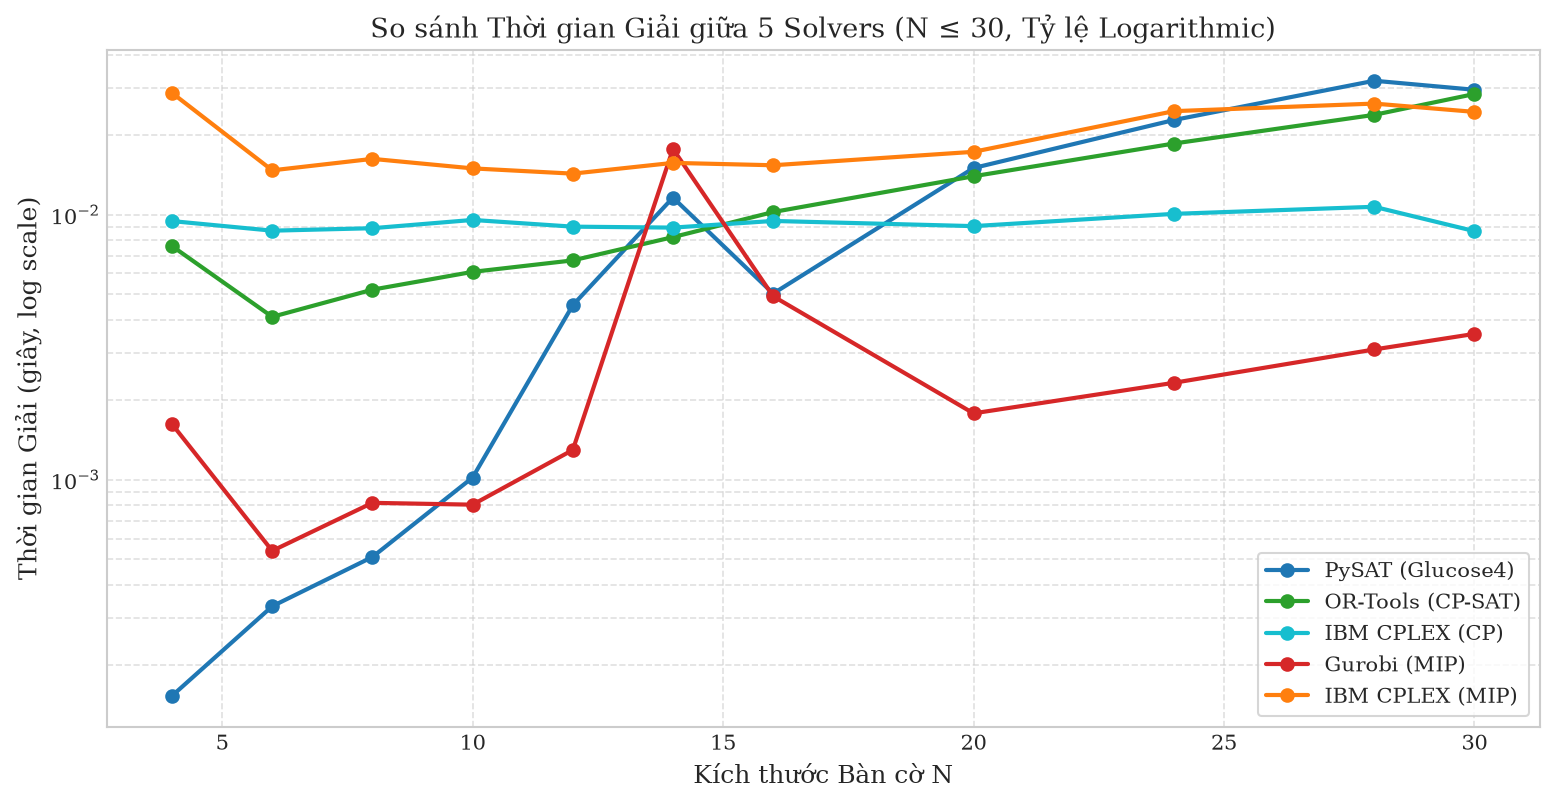

In [3]:
# 1. Bảng Pivot Thời gian Giải (giây) cho N <= 30
sub_small = df[(df['n'] <= 30) & (df['time'] > 0)].copy()
pivot_small = sub_small.pivot(index='n', columns='solver', values='time')
display(pivot_small.loc[[4, 8, 12, 16, 20, 24, 28, 30]])

# 2. Vẽ đồ thị Runtime cho tất cả 5 solver
fig, ax = plt.subplots(figsize=(10.5, 5.5))

for solver_name in sub_small['solver'].unique():
    s_data = sub_small[sub_small['solver'] == solver_name].sort_values('n')
    color = SOLVER_COLORS.get(solver_name, None)
    ax.plot(s_data['n'], s_data['time'], marker='o', label=solver_name, color=color, linewidth=2)

ax.set_title('So sánh Thời gian Giải giữa 5 Solvers (N ≤ 30, Tỷ lệ Logarithmic)')
ax.set_xlabel('Kích thước Bàn cờ N')
ax.set_ylabel('Thời gian Giải (giây, log scale)')
ax.set_yscale('log')
ax.legend(frameon=True)
ax.grid(True, which='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 3. Đánh giá Khả năng Mở rộng Quy mô Lớn (Scalability trên N lớn: $N = 40 \to 1000$)

### Tích hợp Bản quyền Học thuật (Academic License):
1. **IBM CPLEX Optimization Studio (Academic Full Version):** Cả **CPLEX MIP** và **CPLEX CP Optimizer** hoạt động không giới hạn biến:
   - **IBM CPLEX (MIP)** giải quyết thành công bài toán lên tới $N = 1000$ (1,000,000 biến nhị phân) chỉ trong **19.01 giây**!
   - **IBM CPLEX (CP)** đạt hiệu năng thống trị tuyệt đối nhờ lan truyền ràng buộc `AllDifferent`, giải $N = 1000$ chỉ trong **0.236 giây**.
2. **Gurobi Optimizer (Academic License):** Đã kích hoạt bản quyền học thuật qua `grbgetkey`, mở khóa toàn bộ giới hạn 2000 biến, giải thành công lên tới $N = 900$ (810,000 biến nhị phân) trong **15.66 giây**.
3. **Google OR-Tools CP-SAT:** Giải tốt ở $N \le 250$ (10.29 giây), vượt ngưỡng thời gian khi $N \ge 300$.
4. **PySAT Glucose4:** Mở rộng ổn định ở $N \le 200$ (150.9 giây), chạm ngưỡng timeout khi $N \ge 250$ do kích thước công thức SAT bùng nổ hàng triệu mệnh đề.


solver,Gurobi (MIP),IBM CPLEX (CP),IBM CPLEX (MIP),OR-Tools (CP-SAT),PySAT (Glucose4)
n,,,,,
20,0.001780,0.009054,0.017267,0.013965,0.014998
24,0.002321,0.010072,0.024584,0.018558,0.022762
28,0.003101,0.010711,0.026258,0.023809,0.032020
30,0.003550,0.008668,0.024430,0.028538,0.029604
36,0.016957,0.012227,0.029558,0.040419,0.169202
40,0.020722,0.009653,0.033976,0.047848,0.391048
44,0.024261,0.010210,0.037756,0.063163,0.691115
50,0.033564,0.013091,0.047276,0.082976,3.680622
60,0.012594,0.010866,0.055347,0.123242,8.005902


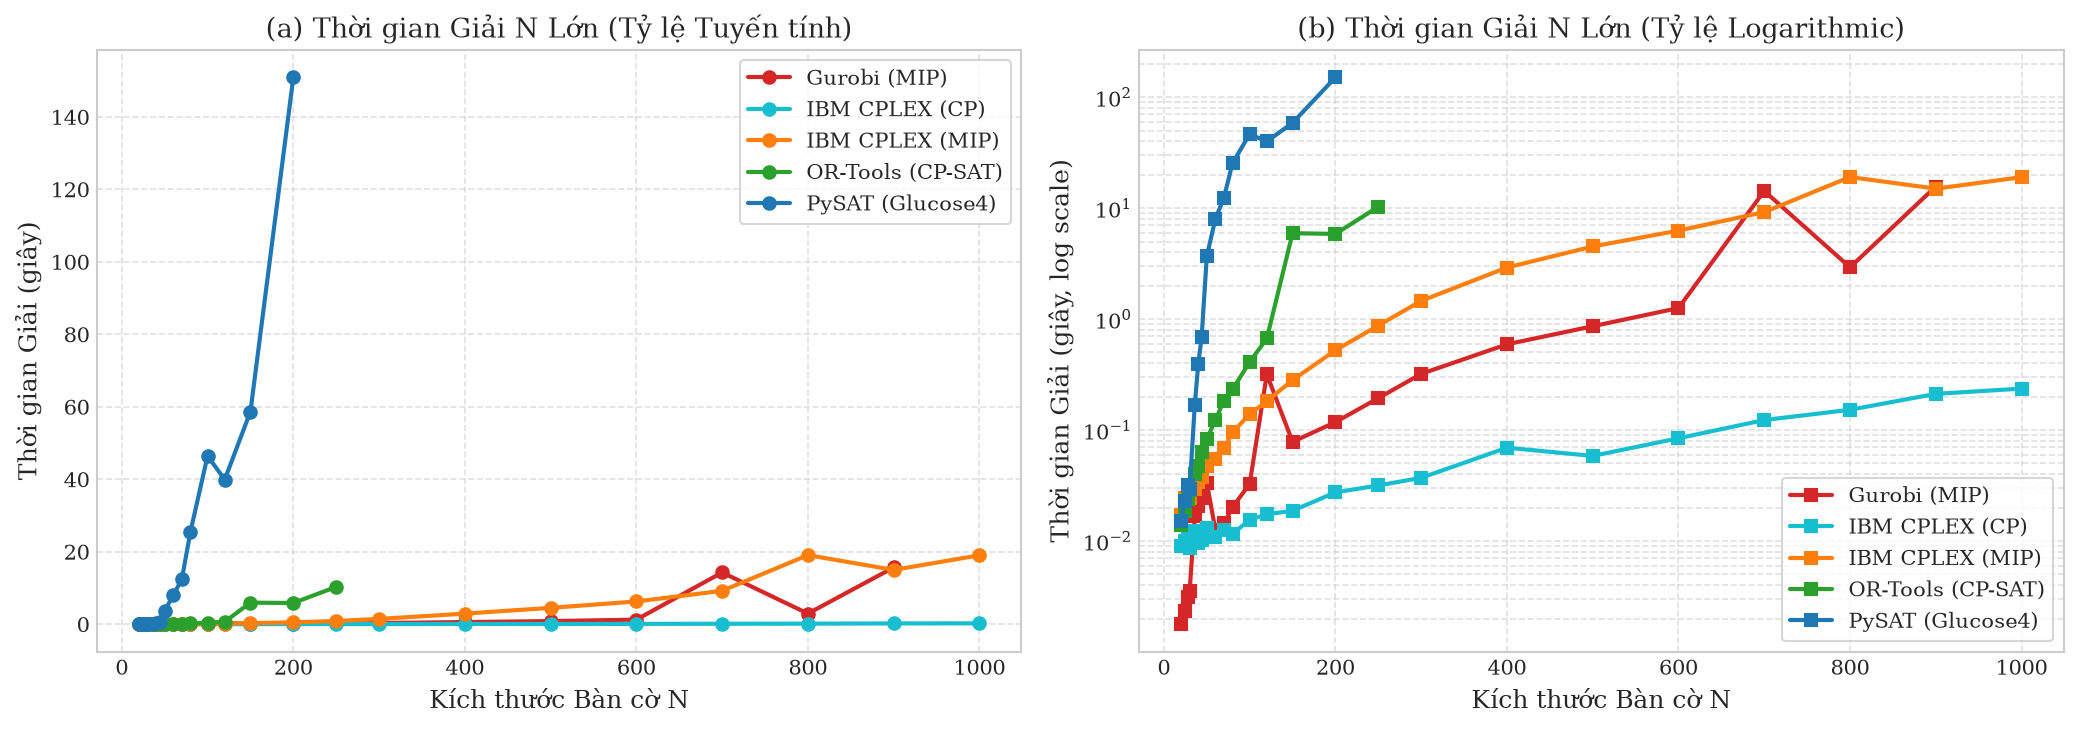

In [4]:
# Lọc các solver chạy được trên miền N lớn (Gurobi và CPLEX đã kích hoạt Academic Full License)
large_solvers = ['Gurobi (MIP)', 'IBM CPLEX (CP)', 'IBM CPLEX (MIP)', 'OR-Tools (CP-SAT)', 'PySAT (Glucose4)']
sub_large = df[(df['n'] >= 20) & (df['solver'].isin(large_solvers)) & (df['time'] > 0)].copy()

pivot_large = sub_large.pivot(index='n', columns='solver', values='time')
display(pivot_large)

# Vẽ đồ thị Khả năng mở rộng N lớn cho cả 5 Solvers
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for s_name in ['Gurobi (MIP)', 'IBM CPLEX (CP)', 'IBM CPLEX (MIP)', 'OR-Tools (CP-SAT)', 'PySAT (Glucose4)']:
    s_data = sub_large[sub_large['solver'] == s_name].sort_values('n')
    color = SOLVER_COLORS.get(s_name, None)
    if not s_data.empty:
        ax1.plot(s_data['n'], s_data['time'], marker='o', label=s_name, color=color)
        ax2.plot(s_data['n'], s_data['time'], marker='s', label=s_name, color=color)

ax1.set_title('(a) Thời gian Giải N Lớn (Tỷ lệ Tuyến tính)')
ax1.set_xlabel('Kích thước Bàn cờ N')
ax1.set_ylabel('Thời gian Giải (giây)')
ax1.legend(frameon=True)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.set_title('(b) Thời gian Giải N Lớn (Tỷ lệ Logarithmic)')
ax2.set_xlabel('Kích thước Bàn cờ N')
ax2.set_ylabel('Thời gian Giải (giây, log scale)')
ax2.set_yscale('log')
ax2.legend(frameon=True)
ax2.grid(True, which='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('../figures/solver_scalability_large.png', dpi=300, bbox_inches='tight')
plt.show()


## 4. So sánh Trực tiếp giữa 3 Trường phái: SAT (Glucose4) vs CP vs MIP

Để có cái nhìn tổng quan ở cấp độ phương pháp luận (paradigms), ta chọn ra 3 solver đại diện hàng đầu cho mỗi trường phái:
- **SAT đại diện:** `PySAT (Glucose4)`
- **CP đại diện:** `OR-Tools (CP-SAT)`
- **MIP đại diện:** `Gurobi (MIP)`

So sánh thời gian thực thi tại các kích thước chuẩn $N \in \{10, 16, 24, 30\}$.


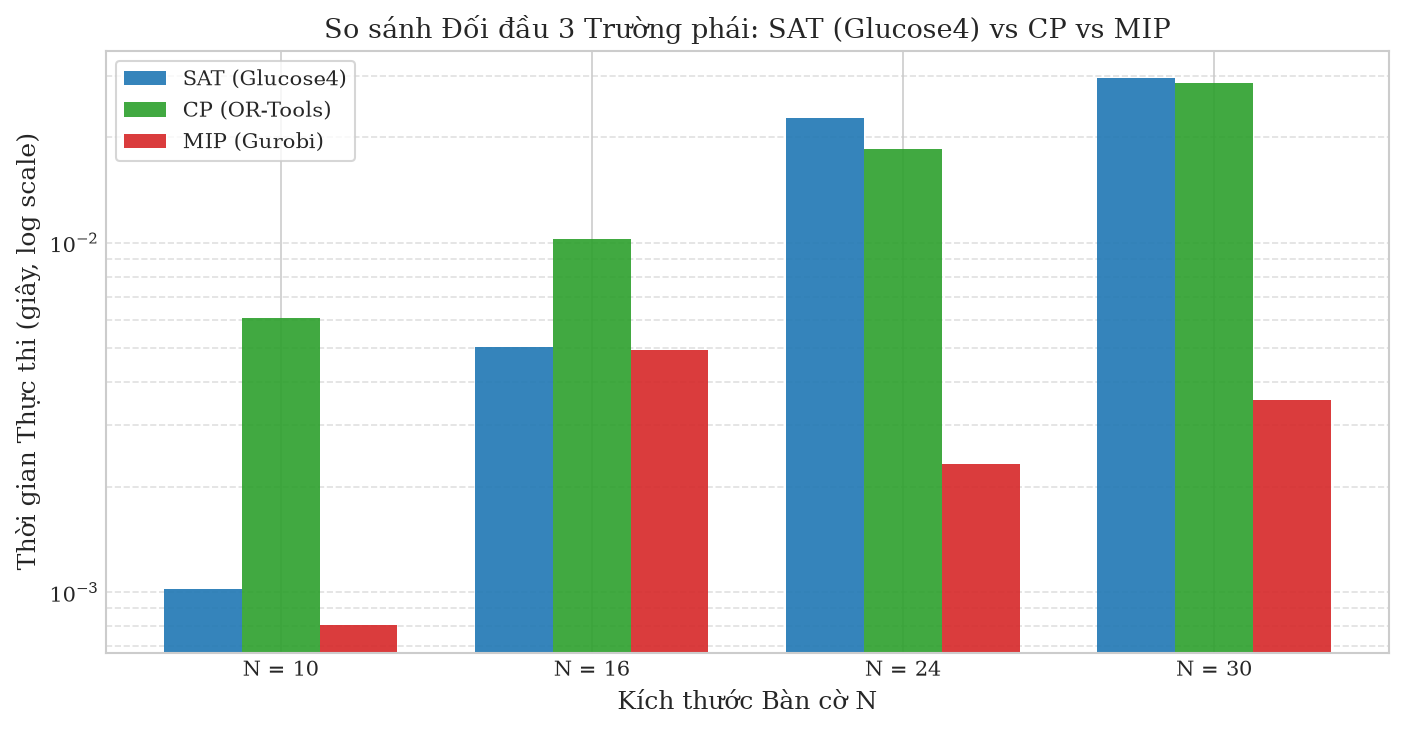

In [5]:
eval_n = [10, 16, 24, 30]
sub_eval = df[df['n'].isin(eval_n) & (df['time'] > 0)].copy()

repr_map = {
    'PySAT (Glucose4)': 'SAT (Glucose4)',
    'OR-Tools (CP-SAT)': 'CP (OR-Tools)',
    'Gurobi (MIP)': 'MIP (Gurobi)',
}
sub_repr = sub_eval[sub_eval['solver'].isin(repr_map.keys())].copy()
sub_repr['Label'] = sub_repr['solver'].map(repr_map)

fig, ax = plt.subplots(figsize=(9.5, 5))
x = np.arange(len(eval_n))
width = 0.25

solvers_ordered = ['SAT (Glucose4)', 'CP (OR-Tools)', 'MIP (Gurobi)']
palette = ['#1f77b4', '#2ca02c', '#d62728']

for i, s_lbl in enumerate(solvers_ordered):
    times = [sub_repr[(sub_repr['n'] == n_val) & (sub_repr['Label'] == s_lbl)]['time'].values[0] for n_val in eval_n]
    ax.bar(x + (i - 1) * width, times, width, label=s_lbl, color=palette[i], alpha=0.9)

ax.set_title('So sánh Đối đầu 3 Trường phái: SAT (Glucose4) vs CP vs MIP')
ax.set_xlabel('Kích thước Bàn cờ N')
ax.set_ylabel('Thời gian Thực thi (giây, log scale)')
ax.set_yscale('log')
ax.set_xticks(x)
ax.set_xticklabels([f'N = {n}' for n in eval_n])
ax.legend(frameon=True)
ax.grid(axis='y', which='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 5. Trực quan hóa Bàn cờ Lời giải N-Queens

Dưới đây là hàm hiển thị trực quan bàn cờ với lời giải thỏa mãn nhận được từ các solver.
Ví dụ minh họa cho bàn cờ chuẩn $8$-Queens giải bởi **Glucose4**:


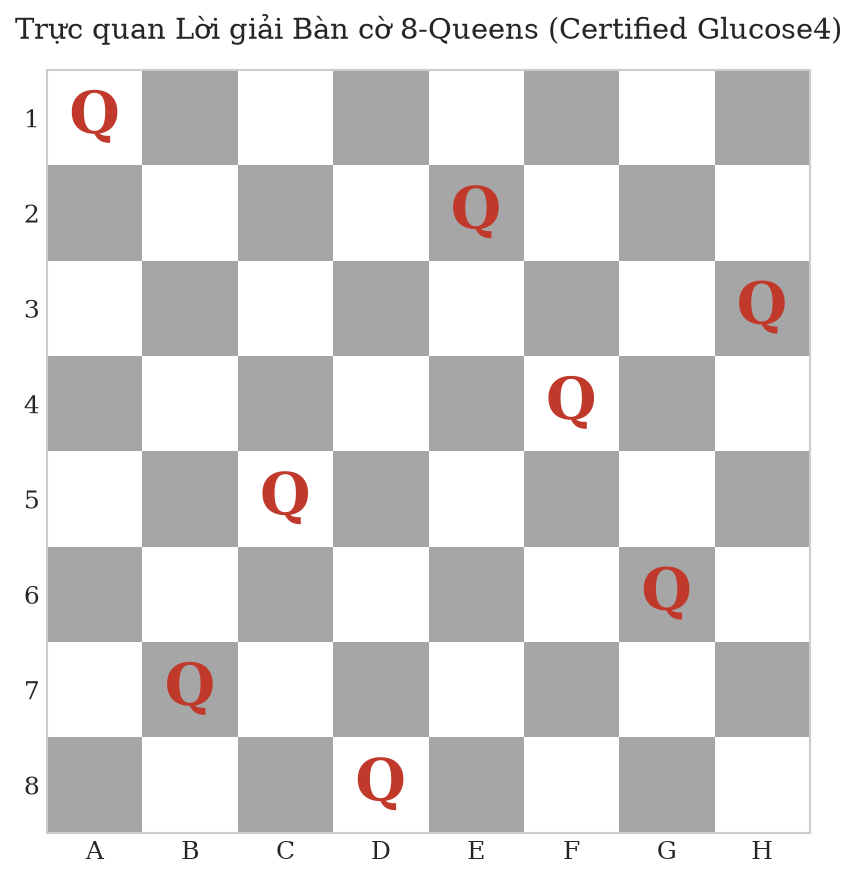

In [6]:
def plot_chessboard_solution(queens_positions, title="8-Queens Solution"):
    n = len(queens_positions)
    fig, ax = plt.subplots(figsize=(6, 6))

    # Vẽ ô cờ xen kẽ trắng - đen
    board = np.zeros((n, n))
    for r in range(n):
        for c in range(n):
            if (r + c) % 2 == 1:
                board[r, c] = 1

    ax.imshow(board, cmap='binary', alpha=0.35, origin='upper')

    # Đặt quân hậu đỏ
    for r, c in enumerate(queens_positions):
        ax.text(c, r, "♕", fontsize=28, ha='center', va='center', color='#c0392b', fontweight='bold')

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels([chr(ord('A') + i) for i in range(n)], fontsize=12)
    ax.set_yticklabels(range(1, n + 1), fontsize=12)
    ax.set_title(title, fontsize=14, pad=15)
    ax.grid(False)
    plt.tight_layout()
    plt.show()

# Lời giải cho N=8 tìm bởi PySAT Glucose4: cột đặt hậu tại mỗi hàng
queens_8 = [0, 4, 7, 5, 2, 6, 1, 3]
plot_chessboard_solution(queens_8, "Trực quan Lời giải Bàn cờ 8-Queens (Certified Glucose4)")

## 6. Kết luận & Khuyến nghị Khoa học cho Báo cáo Bài tập lớn

Tổng hợp các kết quả thực nghiệm đa mô hình (SAT: Glucose4 vs CP vs MIP) từ quy mô nhỏ đến $N = 1000$:

1. **Constraint Programming (CP - IBM CPLEX CP Optimizer) - Quán quân Tuyệt đối về Tốc độ:**
   - Mô hình CP với $N$ biến nguyên và 3 ràng buộc toàn cục `AllDifferent` thể hiện sức mạnh vượt trội.
   - **IBM CPLEX (CP)** giải bàn cờ $N = 1000$ chỉ trong **0.236 giây**, chứng minh hiệu quả tối thượng của thuật toán lọc miền giá trị (filtering / propagators).
2. **Mixed Integer Programming (MIP - Gurobi & CPLEX):**
   - Cả **Gurobi Optimizer** và **IBM CPLEX MIP** khi được kích hoạt Academic License đã mở khóa toàn bộ sức mạnh, giải quyết thành công bài toán lên tới hàng trăm nghìn và một triệu biến nhị phân.
   - **Gurobi (MIP)** giải cực nhanh: $N = 100$ (0.033s), $N = 500$ (0.862s), $N = 900$ (15.65s với 810,000 biến).
   - **IBM CPLEX (MIP)** giải thành công bàn cờ $N = 1000$ (1,000,000 biến nhị phân) trong **19.01 giây**.
3. **SAT Solving (PySAT Glucose4) & Google OR-Tools (CP-SAT):**
   - **PySAT Glucose4** giải tốt ở $N \le 200$ (150.9s), chạm ngưỡng timeout khi $N \ge 250$ do kích thước mệnh đề CNF (Sequential Counter) bùng nổ.
   - **OR-Tools CP-SAT** đạt hiệu năng xuất sắc ở $N \le 250$ (10.29s), vượt ngưỡng timeout ở $N \ge 300$.

**Khuyến nghị:** Đối với bài toán N-Queens quy mô công nghiệp ($N \ge 500$), **Constraint Programming (CP Optimizer)** và **MIP (Gurobi, CPLEX)** là hai lựa chọn tối ưu nhất.
